1. Load the data

In [1]:
import pandas as pd

df_raw = pd.read_csv("timesData.csv")
df = df_raw.copy()
df_raw.head()

,world_rank,university_name,country,teaching,international,research,citations,income,total_score,num_students,student_staff_ratio,international_students,female_male_ratio,year
0,1,Harvard University,United States of America,99.7,72.4,98.7,98.8,34.5,96.1,"20,152",8.9,25%,NaN,2011
1,2,California Institute of Technology,United States of America,97.7,54.6,98.0,99.9,83.7,96.0,"2,243",6.9,27%,33 : 67,2011
2,3,Massachusetts Institute of Technology,United States of America,97.8,82.3,91.4,99.9,87.5,95.6,"11,074",9.0,33%,37 : 63,2011
3,4,Stanford University,United States of America,98.3,29.5,98.1,99.2,64.3,94.3,"15,596",7.8,22%,42 : 58,2011
4,5,Princeton University,United States of America,90.9,70.3,95.4,99.9,-,94.2,"7,929",8.4,27%,45 : 55,2011


2. Inspect the data

In [2]:
print(df.shape)
df.info()

(2603, 14)
<class 'pandas.DataFrame'>
RangeIndex: 2603 entries, 0 to 2602
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   world_rank              2603 non-null   str    
 1   university_name         2603 non-null   str    
 2   country                 2603 non-null   str    
 3   teaching                2603 non-null   float64
 4   international           2603 non-null   str    
 5   research                2603 non-null   float64
 6   citations               2603 non-null   float64
 7   income                  2603 non-null   str    
 8   total_score             2603 non-null   str    
 9   num_students            2544 non-null   str    
 10  student_staff_ratio     2544 non-null   float64
 11  international_students  2536 non-null   str    
 12  female_male_ratio       2370 non-null   str    
 13  year                    2603 non-null   int64  
dtypes: float64(4), int64(1), str(9)
memory u

In [3]:
print("Missing values (NaN) per column:")
print(df.isnull().sum())

print("\nNumber of '-' values per column:")
print((df == "-").sum())

print("\nNumber of duplicated rows:")
print(df.duplicated().sum())

Missing values (NaN) per column:
world_rank                  0
university_name             0
country                     0
teaching                    0
international               0
research                    0
citations                   0
income                      0
total_score                 0
num_students               59
student_staff_ratio        59
international_students     67
female_male_ratio         233
year                        0
dtype: int64

Number of '-' values per column:
world_rank                   0
university_name              0
country                      0
teaching                     0
international                9
research                     0
citations                    0
income                     218
total_score               1402
num_students                 0
student_staff_ratio          0
international_students       0
female_male_ratio            3
year                         0
dtype: int64

Number of duplicated rows:
0


3. Clean: replace "-" with real missing values

In [4]:
import numpy as np
df_raw = df.copy()

df = df.replace("-", np.nan)

missing = df.isnull().sum()
print("Columns with missing values after replace:")
print(missing[missing > 0])

Columns with missing values after replace:
international                9
income                     218
total_score               1402
num_students                59
student_staff_ratio         59
international_students      67
female_male_ratio          236
dtype: int64


In [5]:
df.select_dtypes(include="object").head(10)

C:\Users\S4C\AppData\Local\Temp\ipykernel_7356\2626710375.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object").head(10)


,world_rank,university_name,country,international,income,total_score,num_students,international_students,female_male_ratio
0,1,Harvard University,United States of America,72.4,34.5,96.1,"20,152",25%,NaN
1,2,California Institute of Technology,United States of America,54.6,83.7,96.0,"2,243",27%,33 : 67
2,3,Massachusetts Institute of Technology,United States of America,82.3,87.5,95.6,"11,074",33%,37 : 63
3,4,Stanford University,United States of America,29.5,64.3,94.3,"15,596",22%,42 : 58
4,5,Princeton University,United States of America,70.3,NaN,94.2,"7,929",27%,45 : 55
5,6,University of Cambridge,United Kingdom,77.7,57.0,91.2,"18,812",34%,46 : 54
6,6,University of Oxford,United Kingdom,77.2,73.5,91.2,"19,919",34%,46 : 54
7,8,"University of California, Berkeley",United States of America,39.6,NaN,91.1,"36,186",15%,50 : 50
8,9,Imperial College London,United Kingdom,90.0,92.9,90.6,"15,060",51%,37 : 63
9,10,Yale University,United States of America,59.2,NaN,89.5,"11,751",20%,50 : 50


4. Clean: convert text columns to numbers

In [6]:
for col in ["international", "income", "total_score"]:
    df[col] = pd.to_numeric(df[col])

print(df[["international", "income", "total_score"]].dtypes)

international    float64
income           float64
total_score      float64
dtype: object


In [7]:
print(df[["num_students", "international_students", "female_male_ratio"]].head(5))

df["num_students"] = df["num_students"].str.replace(",", "").astype(float)
df["international_students"] = df["international_students"].str.replace("%", "").astype(float)

print(df[["num_students", "international_students"]].dtypes)
print(df[["num_students", "international_students"]].isnull().sum())

  num_students international_students female_male_ratio
0       20,152                    25%               NaN
1        2,243                    27%           33 : 67
2       11,074                    33%           37 : 63
3       15,596                    22%           42 : 58
4        7,929                    27%           45 : 55
num_students              float64
international_students    float64
dtype: object
num_students              59
international_students    67
dtype: int64


In [8]:
df["female_pct"] = df["female_male_ratio"].str.split(":").str[0].str.strip().astype(float)

print(df[["female_male_ratio", "female_pct"]].head(5))
print("Missing female_pct:", df["female_pct"].isnull().sum())

  female_male_ratio  female_pct
0               NaN         NaN
1           33 : 67        33.0
2           37 : 63        37.0
3           42 : 58        42.0
4           45 : 55        45.0
Missing female_pct: 236


5. Check the ranges after cleaning

In [9]:
df.describe()

,teaching,international,research,citations,income,total_score,num_students,student_staff_ratio,international_students,year,female_pct
count,2603.000000,2594.000000,2603.000000,2603.000000,2385.000000,1201.000000,2544.000000,2544.000000,2536.000000,2603.000000,2367.000000
mean,37.801498,52.007440,35.910257,60.921629,48.979874,59.846128,23873.758648,18.445283,15.444006,2014.075682,49.683988
std,17.604218,22.103825,21.254805,23.073219,21.179938,12.803446,17675.946877,11.458698,10.591464,1.685733,10.859621
min,9.900000,7.100000,2.900000,1.200000,24.200000,41.400000,462.000000,0.600000,0.000000,2011.000000,1.000000
25%,24.700000,33.425000,19.600000,45.500000,33.000000,50.300000,12637.750000,11.975000,8.000000,2013.000000,46.000000
50%,33.900000,50.300000,30.500000,62.500000,41.000000,56.000000,20851.000000,16.100000,13.000000,2014.000000,52.000000
75%,46.400000,69.000000,47.250000,79.050000,59.000000,66.200000,29991.000000,21.500000,21.000000,2016.000000,56.000000
max,99.700000,100.000000,99.400000,100.000000,100.000000,96.100000,379231.000000,162.600000,82.000000,2016.000000,100.000000


6. Decide how to handle missing values and save the clean files

In [10]:
df = df.drop(columns=["female_male_ratio"])

df_model = df.dropna(subset=["total_score"])

print("All rows:", df.shape[0])
print("Rows with total_score:", df_model.shape[0])

missing = df_model.isnull().sum()
print("\nMissing values in df_model:")
print(missing[missing > 0])

All rows: 2603
Rows with total_score: 1201

Missing values in df_model:
international               9
income                    140
num_students               19
student_staff_ratio        19
international_students     20
female_pct                123
dtype: int64


In [11]:
df.to_csv("times_clean.csv", index=False)
df_model.to_csv("times_model.csv", index=False)

print(pd.read_csv("times_clean.csv").shape)
print(pd.read_csv("times_model.csv").shape)

(2603, 14)
(1201, 14)


7. Advanced Python

In [12]:
def clean_number(text: str) -> float:
    """Turn text like '20,152' or '25%' into a float. Return NaN if it fails."""
    try:
        return float(str(text).replace(",", "").replace("%", ""))
    except ValueError:
        return np.nan


samples = ["20,152", "25%", "-", "33.5"]
cleaned = [clean_number(s) for s in samples]
print(cleaned)

[20152.0, 25.0, nan, 33.5]


In [13]:
size_label = lambda n: np.nan if pd.isnull(n) else ("Small" if n < 10000 else "Medium" if n < 25000 else "Large")
print(df["num_students"].apply(size_label).value_counts())


def high_score_universities(data: pd.DataFrame, min_score: float):
    for _, row in data.iterrows():
        if row["total_score"] >= min_score:
            yield row["university_name"], row["total_score"]


gen = high_score_universities(df_model, 90)
print(next(gen))
print(next(gen))
print(next(gen))

num_students
Medium    1194
Large      975
Small      375
Name: count, dtype: int64
('Harvard University', 96.1)
('California Institute of Technology', 96.0)
('Massachusetts Institute of Technology', 95.6)


8. Environment report

In [14]:
import sys
import matplotlib
import numpy as np
import pandas as pd

print("Python:", sys.version)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", matplotlib.__version__)

Python: 3.14.10 (tags/v3.14.10:b703b2c, Oct 25 2026, 17:36:52) [MSC v.1944 64 bit (AMD64)]
pandas: 3.1.1
numpy: 2.5.5
matplotlib: 3.11.2


In [15]:
with open("requirements.txt", "w") as f:
    f.write(f"pandas=={pd.__version__}\n")
    f.write(f"numpy=={np.__version__}\n")
    f.write(f"matplotlib=={matplotlib.__version__}\n")

print(open("requirements.txt").read())

pandas==3.1.1
numpy==2.5.5
matplotlib==3.11.2



In [16]:
import sys

print(sys.prefix)
print(sys.base_prefix)

c:\Program Files\Python314
c:\Program Files\Python314



9. Load the clean data

In [17]:
import pandas as pd
import numpy as np

data = pd.read_csv("times_clean.csv")
print(data.shape)
data.head(3)

(2603, 14)


,world_rank,university_name,country,teaching,international,research,citations,income,total_score,num_students,student_staff_ratio,international_students,year,female_pct
0,1,Harvard University,United States of America,99.7,72.4,98.7,98.8,34.5,96.1,20152.0,8.9,25.0,2011,NaN
1,2,California Institute of Technology,United States of America,97.7,54.6,98.0,99.9,83.7,96.0,2243.0,6.9,27.0,2011,33.0
2,3,Massachusetts Institute of Technology,United States of America,97.8,82.3,91.4,99.9,87.5,95.6,11074.0,9.0,33.0,2011,37.0


10. Filtering

In [18]:
top_2016 = data[(data["year"] == 2016) & (data["total_score"] >= 70)]
top_2016 = top_2016.sort_values(by="total_score", ascending=False)

print(top_2016.shape)
top_2016[["university_name", "country", "total_score"]].head(10)

(48, 14)


,university_name,country,total_score
1803,California Institute of Technology,United States of America,95.2
1804,University of Oxford,United Kingdom,94.2
1805,Stanford University,United States of America,93.9
1806,University of Cambridge,United Kingdom,92.8
1807,Massachusetts Institute of Technology,United States of America,92.0
1808,Harvard University,United States of America,91.6
1809,Princeton University,United States of America,90.1
1810,Imperial College London,United Kingdom,89.1
1811,ETH Zurich – Swiss Federal Institute of Techno...,Switzerland,88.3
1812,University of Chicago,United States of America,87.9


11. GroupBy: average score per country

In [19]:
country_stats = data.groupby("country")["total_score"].agg(["count", "mean"])
country_stats = country_stats.rename(columns={"count": "n_scored", "mean": "avg_score"})
country_stats = country_stats[country_stats["n_scored"] >= 5]
country_stats = country_stats.sort_values(by="avg_score", ascending=False).round(1)

print(country_stats.shape)
country_stats.head(10)

(26, 2)


,n_scored,avg_score
country,,
Singapore,12,65.6
United States of America,437,64.5
China,18,61.3
Switzerland,41,61.0
Canada,48,61.0
Hong Kong,22,60.2
Australia,45,60.1
Japan,27,59.5
United Kingdom,186,59.0


 12. Merge

In [20]:
country_stats = country_stats.reset_index()

merged = pd.merge(data, country_stats[["country", "avg_score"]], on="country", how="left")

print(merged.shape)
merged[["university_name", "country", "total_score", "avg_score"]].head(5)

(2603, 15)


,university_name,country,total_score,avg_score
0,Harvard University,United States of America,96.1,64.5
1,California Institute of Technology,United States of America,96.0,64.5
2,Massachusetts Institute of Technology,United States of America,95.6,64.5
3,Stanford University,United States of America,94.3,64.5
4,Princeton University,United States of America,94.2,64.5


13. Pivot table

In [21]:
top_countries = country_stats["country"].head(10)

pivot = pd.pivot_table(
    data[data["country"].isin(top_countries)],
    values="total_score",
    index="country",
    columns="year",
    aggfunc="mean",
).round(1)

pivot

year,2011,2012,2013,2014,2015,2016
country,,,,,,
Australia,59.8,57.5,62.1,57.7,58.7,64.2
Canada,59.8,59.4,63.0,60.2,59.5,64.7
China,58.6,55.9,68.9,64.2,58.8,71.0
Hong Kong,63.8,55.8,60.7,59.9,57.7,64.2
Japan,60.5,58.7,60.8,57.6,57.4,65.5
Singapore,61.0,58.0,68.4,64.8,67.8,73.7
South Korea,59.4,56.4,61.9,58.7,60.2,55.8
Switzerland,62.1,59.8,61.6,58.5,60.7,63.6
United Kingdom,59.5,56.6,60.1,56.6,58.9,62.0


14. NumPy calculations

In [22]:
scores = data["total_score"].dropna().to_numpy()

print("Mean:", round(np.mean(scores), 2))
print("Median:", np.median(scores))
print("Std:", round(np.std(scores), 2))
print("25th and 75th percentile:", np.percentile(scores, [25, 75]))

pair = data[["student_staff_ratio", "total_score"]].dropna()
corr = np.corrcoef(pair["student_staff_ratio"].to_numpy(), pair["total_score"].to_numpy())[0, 1]
print("Correlation (staff ratio vs score):", round(corr, 3))

z = (scores - np.mean(scores)) / np.std(scores)
print("Universities with z-score above 2:", (z > 2).sum())

Mean: 59.85
Median: 56.0
Std: 12.8
25th and 75th percentile: [50.3 66.2]
Correlation (staff ratio vs score): -0.256
Universities with z-score above 2: 84


15. Visualisations

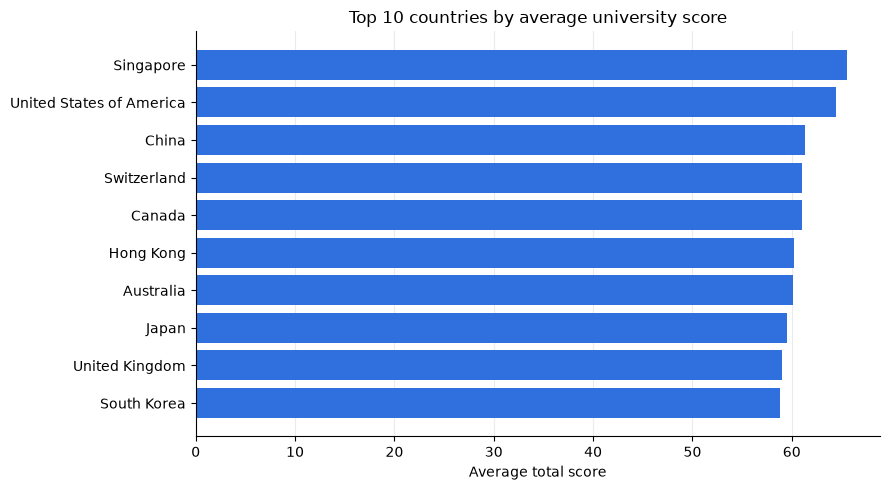

                    country  n_scored  avg_score
0                 Singapore        12       65.6
1  United States of America       437       64.5
2                     China        18       61.3
3               Switzerland        41       61.0
4                    Canada        48       61.0
5                 Hong Kong        22       60.2
6                 Australia        45       60.1
7                     Japan        27       59.5
8            United Kingdom       186       59.0
9               South Korea        23       58.8


In [23]:
import matplotlib.pyplot as plt

top10 = country_stats.head(10)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top10["country"], top10["avg_score"], color="#2F6FDE")
ax.invert_yaxis()
ax.set_title("Top 10 countries by average university score")
ax.set_xlabel("Average total score")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

print(top10)

**Insight**: Singapore has the highest average score (65.6), followed by the United States (64.5) and China (61.3). However, the three averages rest on very different sample sizes: Singapore is based on only 12 scored universities and China on 18, while the United States is based on 437. The US figure is therefore the most reliable, and the averages of small countries can change a lot if one university is added or removed. Only universities that have a `total_score` are included, so the result describes the scored universities, not all universities.

Plot 2: Number of students vs. total score

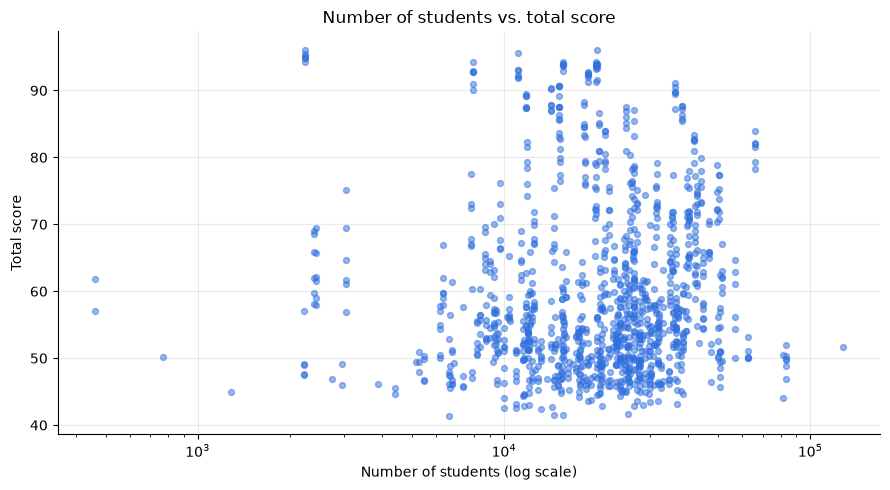

Points plotted: 1182
Correlation: 0.034
Correlation (log of students): 0.02


In [24]:
size_pair = data[["num_students", "total_score"]].dropna()

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(size_pair["num_students"], size_pair["total_score"], s=18, alpha=0.5, color="#2F6FDE")
ax.set_xscale("log")
ax.set_title("Number of students vs. total score")
ax.set_xlabel("Number of students (log scale)")
ax.set_ylabel("Total score")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

print("Points plotted:", len(size_pair))
print("Correlation:", round(np.corrcoef(size_pair["num_students"], size_pair["total_score"])[0, 1], 3))
print("Correlation (log of students):", round(np.corrcoef(np.log10(size_pair["num_students"]), size_pair["total_score"])[0, 1], 3))

**Insight:** The correlation between the number of students and the total score is almost zero (r = 0.034, 1,182 universities). This means that smaller universities do not score better, and larger universities do not score worse: size alone does not explain the score. The log scale on the x-axis is used because a few universities are much larger than the rest.

Plot 3: Students per staff member vs. total score

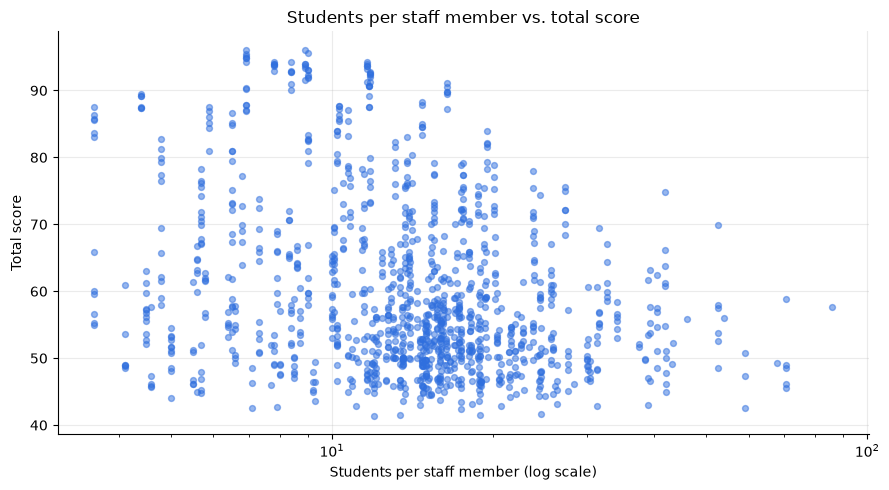

Points plotted: 1182
Correlation: -0.256


In [25]:
ratio_pair = data[["student_staff_ratio", "total_score"]].dropna()

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(ratio_pair["student_staff_ratio"], ratio_pair["total_score"], s=18, alpha=0.5, color="#2F6FDE")
ax.set_xscale("log")
ax.set_title("Students per staff member vs. total score")
ax.set_xlabel("Students per staff member (log scale)")
ax.set_ylabel("Total score")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

print("Points plotted:", len(ratio_pair))
print("Correlation:", round(np.corrcoef(ratio_pair["student_staff_ratio"], ratio_pair["total_score"])[0, 1], 3))


**Insight:** There is a weak negative relationship between students per staff member and the total score (r = -0.256, 1,182 universities). Universities with fewer students per staff member tend to have higher scores. The relationship is weak (about 7% of the variation, since r² is about 0.07), so it is only one of several factors. A correlation does not prove that lowering the ratio would raise the score.

Plot 4: Percentage of international students vs. total score

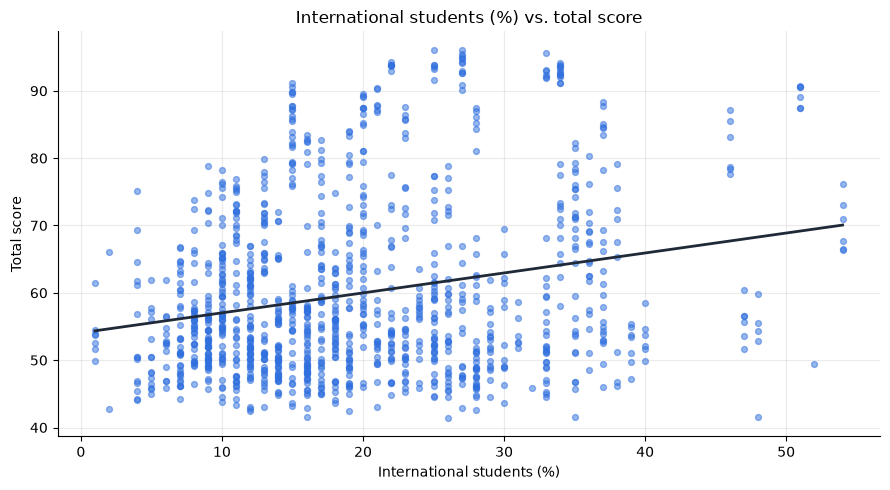

Points plotted: 1181
Slope: 0.296
Correlation: 0.235


In [26]:
intl_pair = data[["international_students", "total_score"]].dropna()
x = intl_pair["international_students"].to_numpy()
y = intl_pair["total_score"].to_numpy()

slope, intercept = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 100)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(x, y, s=18, alpha=0.5, color="#2F6FDE")
ax.plot(xs, slope * xs + intercept, color="#1F2937", linewidth=2)
ax.set_title("International students (%) vs. total score")
ax.set_xlabel("International students (%)")
ax.set_ylabel("Total score")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

print("Points plotted:", len(intl_pair))
print("Slope:", round(slope, 3))
print("Correlation:", round(np.corrcoef(x, y)[0, 1], 3))

**Insight:** The share of international students has a weak positive relationship with the total score (r = 0.235, 1,181 universities), and the trend line slopes upward. Universities with more international students tend to score somewhat higher, but there is a wide spread around the line, so this feature alone cannot predict the score well.

Plot 5: Average score over the years

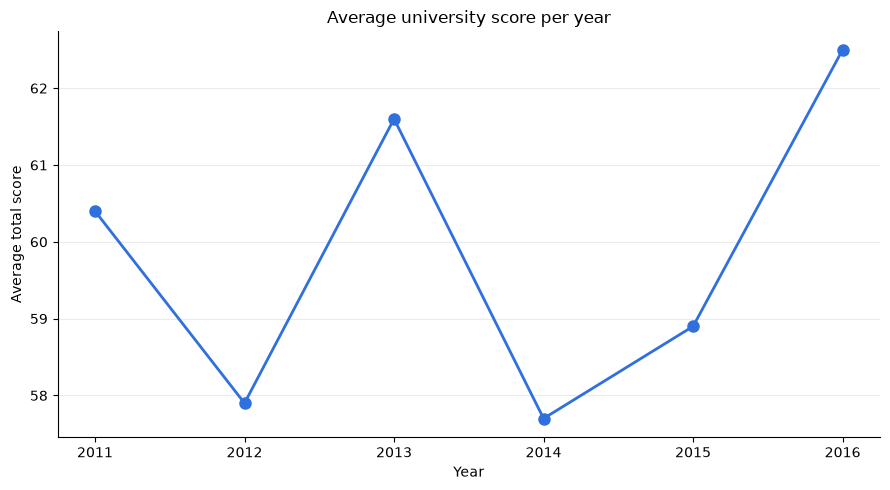

      count  mean
year             
2011    200  60.4
2012    200  57.9
2013    200  61.6
2014    200  57.7
2015    201  58.9
2016    200  62.5


In [27]:
yearly = data.groupby("year")["total_score"].agg(["count", "mean"]).round(1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(yearly.index, yearly["mean"], marker="o", markersize=8, linewidth=2, color="#2F6FDE")
ax.set_title("Average university score per year")
ax.set_xlabel("Year")
ax.set_ylabel("Average total score")
ax.set_xticks(yearly.index)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

print(yearly)

**Insight:** The average score moves up and down between 57.7 (2014) and 62.5 (2016), a range of about 4.8 points, with no steady upward or downward trend across 2011-2016. Each year has about 200 scored universities, and the set of universities is not exactly the same every year, so these changes should not be read as individual universities improving or declining.

In [28]:
print("Top 3 countries:")
print(country_stats[["country", "avg_score", "n_scored"]].head(3))

print("\nPer year:")
print(yearly)

print("\nCorrelation with total_score:")
for col in ["num_students", "student_staff_ratio", "international_students", "female_pct"]:
    p = data[[col, "total_score"]].dropna()
    print(col, "| points:", len(p), "| r =", round(np.corrcoef(p[col], p["total_score"])[0, 1], 3))

Top 3 countries:
                    country  avg_score  n_scored
0                 Singapore       65.6        12
1  United States of America       64.5       437
2                     China       61.3        18

Per year:
      count  mean
year             
2011    200  60.4
2012    200  57.9
2013    200  61.6
2014    200  57.7
2015    201  58.9
2016    200  62.5

Correlation with total_score:
num_students | points: 1182 | r = 0.034
student_staff_ratio | points: 1182 | r = -0.256
international_students | points: 1181 | r = 0.235
female_pct | points: 1078 | r = -0.141
